In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("StudentsPerformance.csv")

df.head()

print(df)


     gender race/ethnicity parental level of education         lunch  \
0    female        group B           bachelor's degree      standard   
1    female        group C                some college      standard   
2    female        group B             master's degree      standard   
3      male        group A          associate's degree  free/reduced   
4      male        group C                some college      standard   
..      ...            ...                         ...           ...   
995  female        group E             master's degree      standard   
996    male        group C                 high school  free/reduced   
997  female        group C                 high school  free/reduced   
998  female        group D                some college      standard   
999  female        group D                some college  free/reduced   

    test preparation course  math score  reading score  writing score  
0                      none          72             72         

In [2]:
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)

In [3]:
df.shape

(1000, 8)

In [4]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')

In [5]:
df.dtypes

gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object

In [6]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [7]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [8]:
df["total score"] = (
    df["math score"]
    + df["reading score"]
    + df["writing score"]
)

df["average score"] = df["total score"] / 3

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total score,average score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [9]:
df["average score"].mean()

np.float64(67.77066666666666)

In [10]:
print("Highest average score:", df["average score"].max())
print("Lowest average score:", df["average score"].min())

Highest average score: 100.0
Lowest average score: 9.0


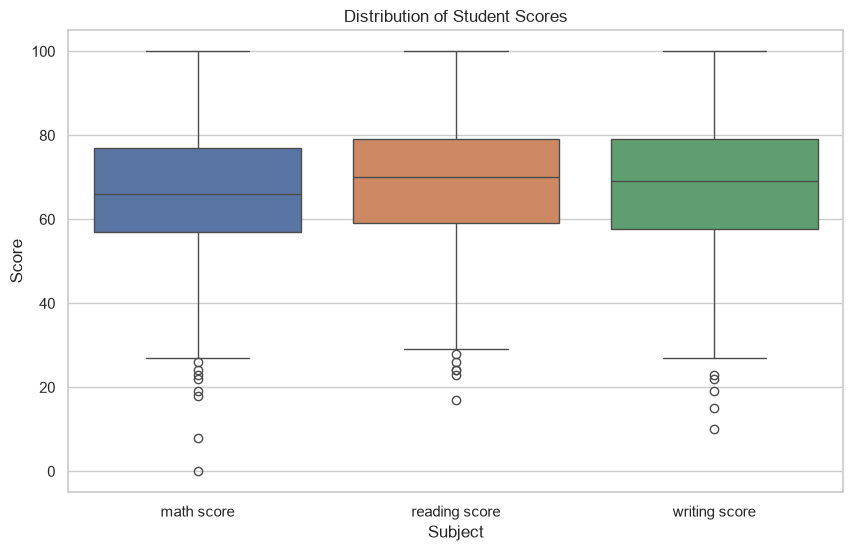

In [11]:
score_columns = [
    "math score",
    "reading score",
    "writing score"
]

plt.figure(figsize=(10, 6))

sns.boxplot(data=df[score_columns])

plt.title("Distribution of Student Scores")
plt.xlabel("Subject")
plt.ylabel("Score")

plt.show()

## Average scores by category

In [12]:
categories = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
]

for cat in categories:
    print(f"Average scores by {cat}:")
    print(df.groupby(cat)[score_columns + ["average score"]].mean().round(2))
    print()

Average scores by gender:
        math score  reading score  writing score  average score
gender                                                         
female       63.63          72.61          72.47          69.57
male         68.73          65.47          63.31          65.84

Average scores by race/ethnicity:
                math score  reading score  writing score  average score
race/ethnicity                                                         
group A              61.63          64.67          62.67          62.99
group B              63.45          67.35          65.60          65.47
group C              64.46          69.10          67.83          67.13
group D              67.36          70.03          70.15          69.18
group E              73.82          73.03          71.41          72.75

Average scores by parental level of education:
                             math score  reading score  writing score  \
parental level of education                               

## Correlation between scores

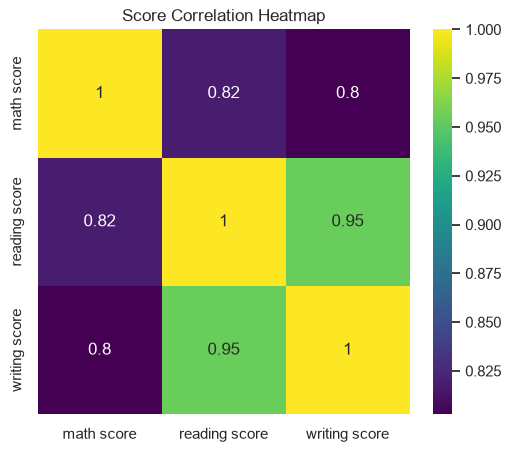

In [13]:
corr = df[score_columns].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="viridis")
plt.title("Score Correlation Heatmap")
plt.show()

## Distribution of average score

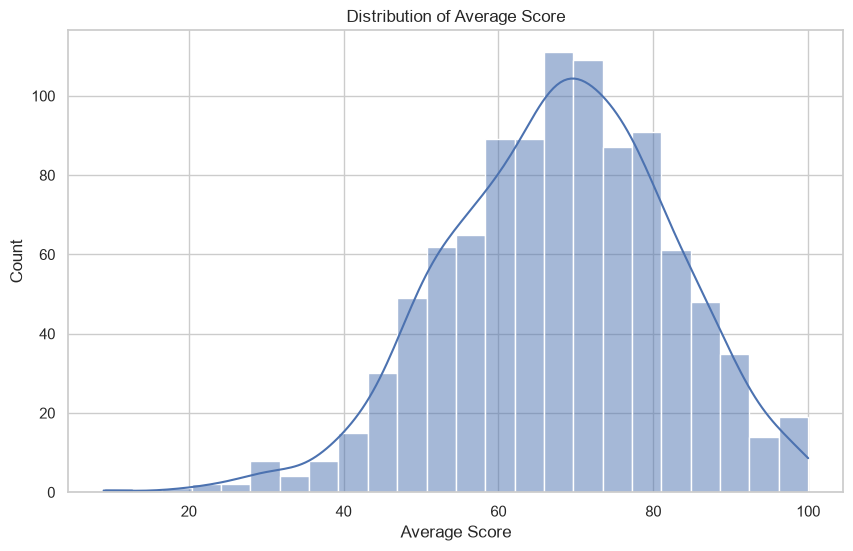

In [14]:
plt.figure(figsize=(10, 6))
sns.histplot(df["average score"], kde=True)
plt.title("Distribution of Average Score")
plt.xlabel("Average Score")
plt.show()

## Average score by gender

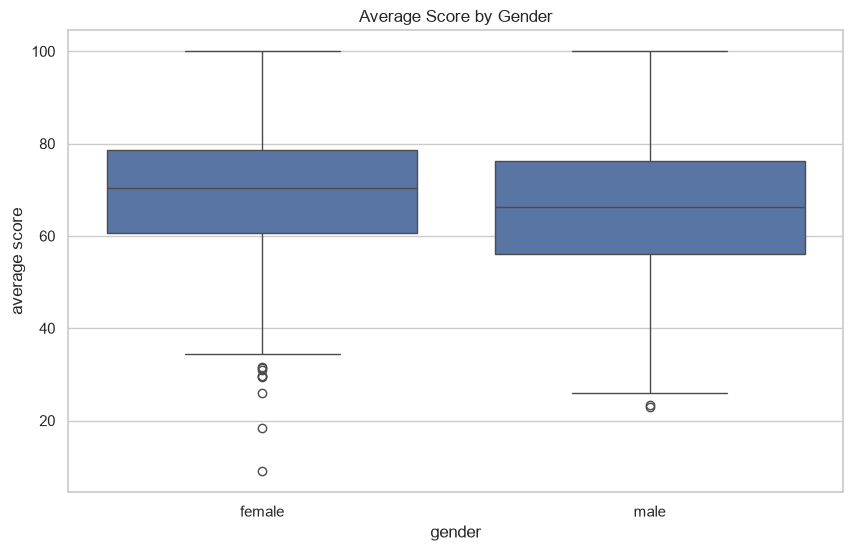

In [15]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="gender", y="average score")
plt.title("Average Score by Gender")
plt.show()

## Average score by test preparation course

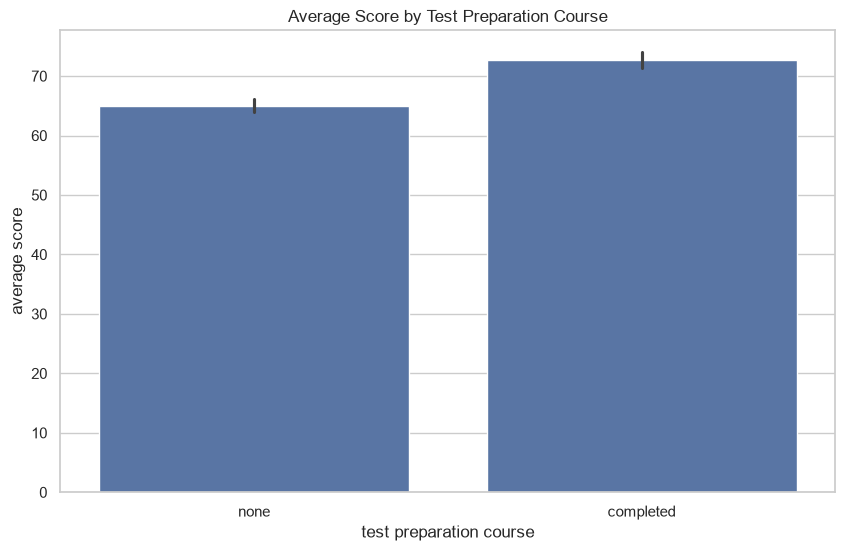

In [16]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x="test preparation course", y="average score")
plt.title("Average Score by Test Preparation Course")
plt.show()